# Eleição Presidencial 2026 — Auditoria adversarial ("advogado do diabo")

**Postura:** este notebook parte do lado de quem quer contestar o resultado e procura **qualquer brecha** — toda
irregularidade aritmética, horário estranho, seção atípica, padrão de dígitos ou correlação suspeita que possa ser usada
para pedir a anulação de urnas ou da eleição.

**Regra do jogo:** uma contestação só sobrevive se resistir a três perguntas. Por isso cada achado é apresentado assim:

| Etapa | Pergunta |
|---|---|
| **Hipótese** | Qual irregularidade estaria acontecendo? |
| **Teste ingênuo** | O que o dado bruto mostra (a versão que circularia em redes sociais)? |
| **Controle** | O padrão persiste quando comparamos com o acaso, com a geografia, com o mesmo município/escola? |
| **Materialidade** | Se *todas* as seções sinalizadas fossem anuladas, o resultado mudaria? |

Um achado só é "forte" se passar no controle **e** for material. Um achado que falha no controle é o tipo de argumento
que é derrubado na primeira perícia — e é útil saber disso antes de usá-lo.

**Contexto jurídico (resumo, não é parecer):** o Código Eleitoral prevê nulidade/anulabilidade de votação em seções
específicas mediante prova de irregularidade concreta (arts. 220–221) e renovação da eleição quando a nulidade atinge
mais da metade dos votos (art. 224). Na prática, portanto, uma brecha precisa (a) ser comprovada seção a seção e
(b) atingir votos suficientes para reverter a margem.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from eleicoes_2026 import analise as A

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40

T = {t: A.carregar_secoes(t) for t in (1, 2)}
TURNOS = [t for t, df in T.items() if df is not None]
FLAGS = {t: {} for t in TURNOS}  # turno -> {critério: máscara booleana de seções}

def sinalizar(t, nome, mascara):
    mascara = mascara.fillna(False).astype(bool)
    FLAGS[t][nome] = mascara
    i = A.impacto(T[t], mascara, nome)
    print(f"[{t}º turno] {nome}: {i['secoes']:,} seções ({i['pct_secoes']:.3f}%), {i['votos_validos']:,} votos válidos | "
          f"líquido p/ vencedor {i['liquido_para_vencedor']:+,} = {i['pct_da_margem']:.2f}% da margem "
          f"→ {'ALTERARIA o resultado' if i['muda_resultado'] else 'não altera o resultado'}")
    return mascara

for t in TURNOS:
    v, s, m = A.margem(T[t])
    print(f"{t}º turno: {v} × {s} — margem de {m:,} votos. Esse é o número que qualquer contestação precisa superar.")
if 2 not in TURNOS:
    print("\n2º turno ainda não disponível: rode `uv run baixar --turno 2 && uv run processar --turno 2` e reexecute.")

1º turno: FLAVIO BOLSONARO × LULA — margem de 2,224,965 votos. Esse é o número que qualquer contestação precisa superar.
2º turno: LULA × FLAVIO BOLSONARO — margem de 4,430,191 votos. Esse é o número que qualquer contestação precisa superar.


## A1. Erros aritméticos no BU
**Hipótese:** BUs com contas que não fecham indicariam adulteração ou falha da urna.
**Teste:** comparecimento + abstenções = aptos; votos totais = comparecimento; comparecimento ≤ aptos.

In [2]:
for t in TURNOS:
    df = T[t]
    display(A.checar_consistencia(df).style.set_caption(f"{t}º turno"))
    m = ((df["qt_comparecimento"] + df["qt_abstencoes"] != df["qt_aptos"]) | (df["votos_total"] != df["qt_comparecimento"])
         | (df["qt_comparecimento"] > df["qt_aptos"]))
    sinalizar(t, "A1 conta não fecha", m)
    if m.any():
        display(df.loc[m, ["sec_id", "qt_aptos", "qt_comparecimento", "qt_abstencoes", "votos_total", "ds_secoes_agregadas"]].head(20))

,secoes_violando,pct
comparecimento + abstenções = aptos,0,0.000000
votos (cand+branco+nulo) = comparecimento,0,0.000000
comparecimento <= aptos,0,0.000000
seção sem aptos,0,0.000000
seção duplicada,0,0.000000
BU emitido antes do encerramento,0,0.000000
encerramento antes da abertura,0,0.000000


[1º turno] A1 conta não fecha: 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado


,secoes_violando,pct
comparecimento + abstenções = aptos,0,0.000000
votos (cand+branco+nulo) = comparecimento,0,0.000000
comparecimento <= aptos,0,0.000000
seção sem aptos,0,0.000000
seção duplicada,0,0.000000
BU emitido antes do encerramento,0,0.000000
encerramento antes da abertura,0,0.000000


[2º turno] A1 conta não fecha: 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado


## A2. Seções "unânimes" ou com zero voto para um finalista
**Hipótese:** seções com ≥ 95% para um candidato, ou com zero votos para um finalista, seriam indício de manipulação.
**Controle:** (i) simetria — isso acontece para os dois lados?; (ii) geografia — onde estão? (aldeias indígenas,
comunidades isoladas e seções pequenas produzem unanimidade legítima); (iii) o mesmo local de votação também é extremo?

In [3]:
for t in TURNOS:
    df = T[t]
    a, b = A.principais(df, 2)
    grande = df["votos_validos"] >= 50
    linhas = []
    for c in (a, b):
        sh = df[c] / df["votos_validos"].replace(0, np.nan)
        linhas += [{"candidato": c, "critério": "≥95% dos válidos (seções ≥50 votos)", "seções": int((grande & (sh >= .95)).sum())},
                   {"candidato": c, "critério": "zero votos (seções ≥50 votos)", "seções": int((grande & (df[c] == 0)).sum())}]
    display(pd.DataFrame(linhas).pivot(index="critério", columns="candidato", values="seções").style.set_caption(f"{t}º turno — simetria"))

    sh_a = df[a] / df["votos_validos"].replace(0, np.nan)
    extremo = grande & ((sh_a >= .95) | (sh_a <= .05))
    # mesmo critério aplicado ao local de votação inteiro: se a escola toda é extrema, é perfil do eleitorado
    loc = df.groupby(A.CHAVE_LOCAL, observed=True)[[a, "votos_validos"]].transform("sum")
    sh_loc = loc[a] / loc["votos_validos"]
    so_a_secao = extremo & sh_loc.between(.15, .85)
    print(f"{t}º turno: {extremo.sum()} seções extremas; destas, {so_a_secao.sum()} estão em locais onde o conjunto NÃO é extremo")
    display(df[extremo].groupby("uf", observed=True).size().sort_values(ascending=False).head(10).rename("seções extremas por UF").to_frame().T)
    sinalizar(t, "A2 seção extrema destoando do próprio local", so_a_secao)
    display(df.loc[so_a_secao, ["sec_id", "nm_municipio", "votos_validos", a, b]].assign(pct_local_a=sh_loc[so_a_secao]).head(15))

candidato,FLAVIO BOLSONARO,LULA
critério,,
zero votos (seções ≥50 votos),65,5
≥95% dos válidos (seções ≥50 votos),20,822


1º turno: 1507 seções extremas; destas, 4 estão em locais onde o conjunto NÃO é extremo


uf,MA,BA,AM,PI,PA,PE,CE,MT,TO,MG
seções extremas por UF,360,263,215,148,106,90,72,38,36,33


[1º turno] A2 seção extrema destoando do próprio local: 4 seções (0.001%), 579 votos válidos | líquido p/ vencedor -373 = -0.02% da margem → não altera o resultado


,sec_id,nm_municipio,votos_validos,FLAVIO BOLSONARO,LULA,pct_local_a
17394,AM-2399-45-52,IPIXUNA,200,9,172,0.172
35819,BA-37591-79-229,NOVA SOURE,160,8,150,0.157
78140,CE-14435-119-310,JARDIM,150,7,140,0.175
349061,RS-85758-148-357,CAMPINAS DO SUL,69,66,1,0.752


candidato,FLAVIO BOLSONARO,LULA
critério,,
zero votos (seções ≥50 votos),88,3
≥95% dos válidos (seções ≥50 votos),39,1707


2º turno: 1746 seções extremas; destas, 2 estão em locais onde o conjunto NÃO é extremo


uf,MA,BA,AM,PI,PA,PE,CE,MT,MS,TO
seções extremas por UF,499,253,232,152,126,99,85,43,41,36


[2º turno] A2 seção extrema destoando do próprio local: 2 seções (0.000%), 271 votos válidos | líquido p/ vencedor +113 = 0.00% da margem → não altera o resultado


,sec_id,nm_municipio,votos_validos,LULA,FLAVIO BOLSONARO,pct_local_a
6298,AL-28835-20-45,TRAIPU,200,191,9,0.799
344716,RS-85758-148-357,CAMPINAS DO SUL,71,1,70,0.251


## A3. Comparecimento anormalmente alto
**Hipótese:** "enchimento de urna" eleva o comparecimento e concentra votos num candidato.
**Teste ingênuo:** seções com comparecimento ≥ 95%. **Controle:** essas seções votam diferente das outras do mesmo
município? (Regressão da % do candidato em comparecimento alto, com efeito fixo de município.)

In [4]:
for t in TURNOS:
    df = T[t]
    a, _ = A.principais(df, 2)
    alto = (df["comparecimento_pct"] >= .95) & (df["qt_aptos"] >= 50)
    d = df[df["votos_validos"] > 0].assign(sh=lambda x: x[a] / x["votos_validos"] * 100, alto=alto.astype(int),
                                            mun=lambda x: x["uf"].astype(str) + x["cd_municipio"].astype(str))
    ingenuo = d.groupby("alto")["sh"].mean()
    print(f"{t}º turno: {alto.sum()} seções com comparecimento ≥95% (aptos ≥ 50)")
    print(f"   ingênuo: % {a} = {ingenuo.get(1, np.nan):.1f} (alto) vs {ingenuo.get(0, np.nan):.1f} (resto)")
    if d["alto"].any():
        fe = A.efeito_dentro_do_grupo(d["sh"], d["alto"], d["mun"], d["votos_validos"])
        print(f"   com efeito fixo de município: diferença = {fe['coef']:+.2f} p.p. "
              f"(IC95% {fe['ic95'][0]:+.2f} a {fe['ic95'][1]:+.2f}; p = {fe['p']:.3g})")
    sinalizar(t, "A3 comparecimento ≥95%", alto)

1º turno: 538 seções com comparecimento ≥95% (aptos ≥ 50)
   ingênuo: % FLAVIO BOLSONARO = 31.6 (alto) vs 46.7 (resto)


   com efeito fixo de município: diferença = -5.71 p.p. (IC95% -6.97 a -4.45; p = 6.88e-19)
[1º turno] A3 comparecimento ≥95%: 538 seções (0.108%), 79,641 votos válidos | líquido p/ vencedor -23,661 = -1.06% da margem → não altera o resultado
2º turno: 620 seções com comparecimento ≥95% (aptos ≥ 50)
   ingênuo: % LULA = 66.8 (alto) vs 52.1 (resto)
   com efeito fixo de município: diferença = +7.33 p.p. (IC95% +5.69 a +8.98; p = 2.12e-18)
[2º turno] A3 comparecimento ≥95%: 620 seções (0.124%), 107,297 votos válidos | líquido p/ vencedor +37,441 = 0.85% da margem → não altera o resultado


## A4. Eleitores liberados sem biometria
**Hipótese:** o mesário libera o voto de quem não teve a digital reconhecida (código de liberação); uso em massa
permitiria votar no lugar de ausentes.
**Teste ingênuo:** correlação entre % liberada sem biometria e % de um candidato. **Controle:** a mesma correlação
**dentro do município** (a biometria falha mais em idosos e trabalhadores manuais, que têm perfil de voto próprio).

1º turno: correlação % sem biometria × % FLAVIO BOLSONARO: ingênua -0.044 | dentro do município -0.020


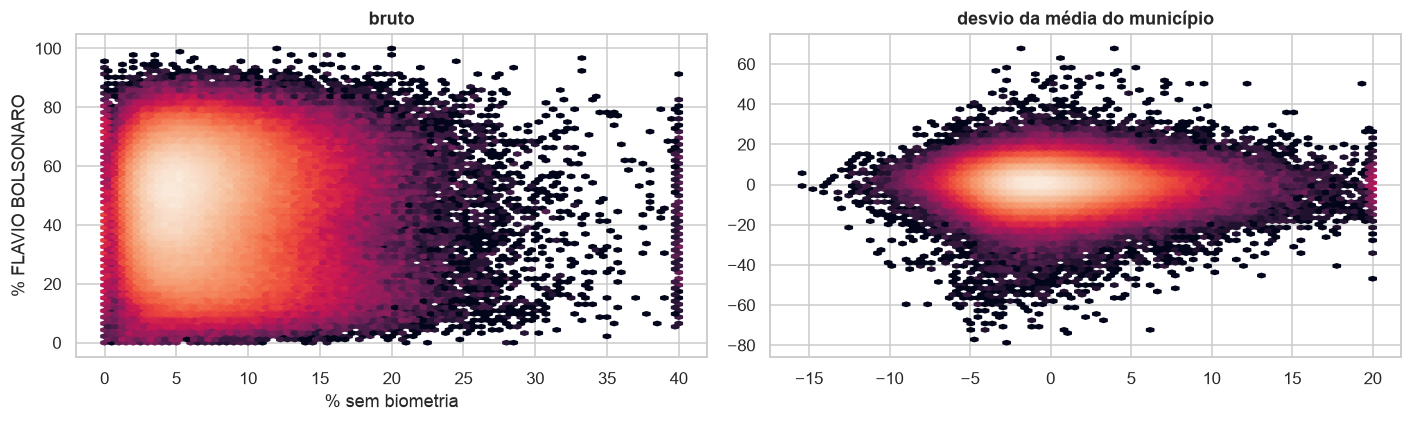

[1º turno] A4 sem biometria > p99,9 (29%): 500 seções (0.100%), 94,718 votos válidos | líquido p/ vencedor -10,294 = -0.46% da margem → não altera o resultado


2º turno: correlação % sem biometria × % LULA: ingênua +0.068 | dentro do município +0.012


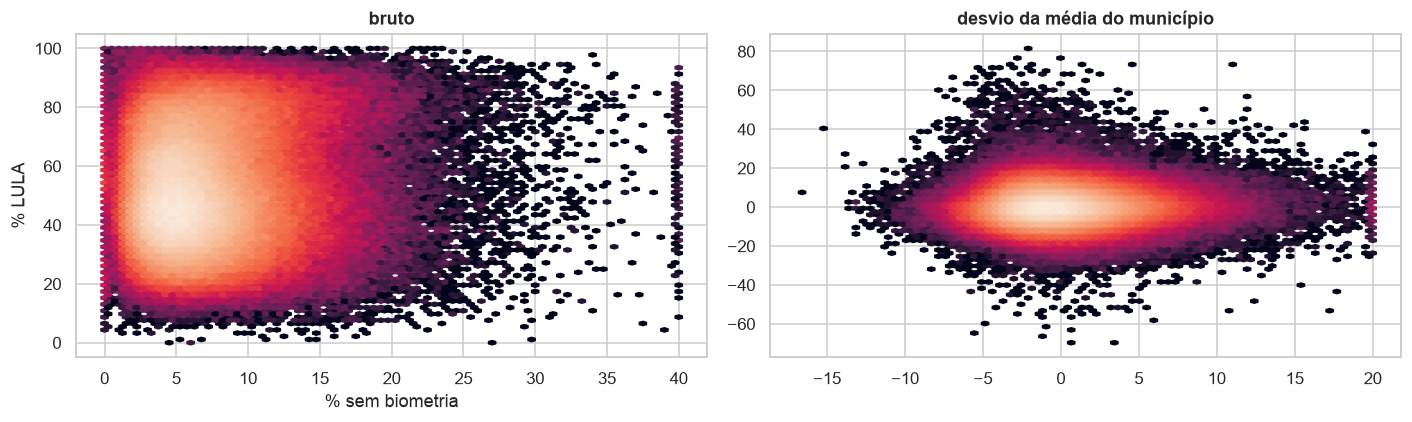

[2º turno] A4 sem biometria > p99,9 (28%): 500 seções (0.100%), 97,545 votos válidos | líquido p/ vencedor +19,403 = 0.44% da margem → não altera o resultado


In [5]:
for t in TURNOS:
    df = T[t]
    a, _ = A.principais(df, 2)
    d = df[(df["votos_validos"] >= 30) & (df["qt_comparecimento"] > 0)].copy()
    d["sem_bio"] = d["qt_biom_sem_hab"] / d["qt_comparecimento"] * 100
    d["sh"] = d[a] / d["votos_validos"] * 100
    d["mun"] = d["uf"].astype(str) + d["cd_municipio"].astype(str)
    r_ing = d[["sem_bio", "sh"]].corr().iloc[0, 1]
    dm = d[["sem_bio", "sh"]] - d.groupby("mun")[["sem_bio", "sh"]].transform("mean")
    r_fe = dm.corr().iloc[0, 1]
    print(f"{t}º turno: correlação % sem biometria × % {a}: ingênua {r_ing:+.3f} | dentro do município {r_fe:+.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hexbin(d["sem_bio"].clip(0, 40), d["sh"], gridsize=80, bins="log"); axes[0].set(title="bruto", xlabel="% sem biometria", ylabel=f"% {a}")
    axes[1].hexbin(dm["sem_bio"].clip(-20, 20), dm["sh"], gridsize=80, bins="log"); axes[1].set(title="desvio da média do município")
    plt.tight_layout(); plt.show()
    lim = d["sem_bio"].quantile(.999)
    sinalizar(t, f"A4 sem biometria > p99,9 ({lim:.0f}%)", df["sec_id"].isin(d.loc[d["sem_bio"] > lim, "sec_id"]))

## A5. Horários fora do padrão e cargas de urna
**Hipótese:** urnas abertas antes das 8h ou encerradas antes das 17h (Brasília), BU emitido antes do encerramento ou
muito depois dele, ou urnas carregadas no dia da eleição (substituição) permitiriam votos fora do controle da mesa.
**Controle:** os horários do BU são locais. Convertemos para Brasília usando o fuso de cada município, inferido pela
hora de abertura mais comum ali (o AM tem dois fusos; uma conversão fixa por UF fazia ~550 seções do oeste do AM
parecerem abrir antes da hora — um falso positivo clássico). Exterior excluído. Encerrar depois das 17h é **legal**
(eleitores na fila votam); encerrar antes só é permitido se todos os eleitores da seção já votaram.

In [6]:
for t in TURNOS:
    df = T[t]
    dia = df["dt_abertura"].dt.normalize().mode()[0]
    h = lambda s: s.dt.hour + s.dt.minute / 60 + s.dt.second / 3600
    crit = {
        "A5a abertura antes de 7h50 (Brasília)": h(df["dt_abertura_bsb"]) < 7 + 50 / 60,
        "A5b encerramento antes de 17h (Brasília)": h(df["dt_encerramento_bsb"]) < 17,
        "A5c BU emitido antes do encerramento": df["dt_emissao_bu"] < df["dt_encerramento"],
        "A5d BU emitido > 2h após encerramento": (df["dt_emissao_bu"] - df["dt_encerramento"]) > pd.Timedelta("2h"),
        "A5e urna carregada no dia da eleição ou depois": df["dt_carga_urna"] >= dia,
        "A5f votação em dia diferente do oficial": df["dt_abertura"].dt.normalize() != dia,
    }
    for nome, m in crit.items():
        sinalizar(t, nome, m & (df["uf"] != "ZZ"))
    m = crit["A5b encerramento antes de 17h (Brasília)"] & (df["uf"] != "ZZ")
    if m.any():
        print("   Encerramento antecipado — comparecimento dessas seções (100% = todos votaram, encerramento antecipado permitido):")
        display(df.loc[m, "comparecimento_pct"].describe().to_frame().T)

[1º turno] A5a abertura antes de 7h50 (Brasília): 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[1º turno] A5b encerramento antes de 17h (Brasília): 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[1º turno] A5c BU emitido antes do encerramento: 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[1º turno] A5d BU emitido > 2h após encerramento: 2 seções (0.000%), 382 votos válidos | líquido p/ vencedor -88 = -0.00% da margem → não altera o resultado
[1º turno] A5e urna carregada no dia da eleição ou depois: 7 seções (0.001%), 1,675 votos válidos | líquido p/ vencedor +684 = 0.03% da margem → não altera o resultado
[1º turno] A5f votação em dia diferente do oficial: 2 seções (0.000%), 518 votos válidos | líquido p/ vencedor +9 = 0.00% da margem → não altera o resultado


[2º turno] A5a abertura antes de 7h50 (Brasília): 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[2º turno] A5b encerramento antes de 17h (Brasília): 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[2º turno] A5c BU emitido antes do encerramento: 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[2º turno] A5d BU emitido > 2h após encerramento: 10 seções (0.002%), 3,090 votos válidos | líquido p/ vencedor -294 = -0.01% da margem → não altera o resultado
[2º turno] A5e urna carregada no dia da eleição ou depois: 5 seções (0.001%), 1,072 votos válidos | líquido p/ vencedor -222 = -0.01% da margem → não altera o resultado
[2º turno] A5f votação em dia diferente do oficial: 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado


## A6. Identificação das urnas
**Hipótese:** a mesma urna física registrada em mais de uma seção, urnas que não sejam "Apurada" (votação em cédula,
urna de contingência) e seções agregadas seriam pontos sem rastreabilidade.

In [7]:
for t in TURNOS:
    df = T[t]
    dup = df["nr_urna_efetivada"].notna() & df.duplicated("nr_urna_efetivada", keep=False)
    sinalizar(t, "A6a mesma urna em mais de uma seção", dup)
    sinalizar(t, "A6b tipo de urna diferente de 'Apurada'", df["ds_tipo_urna"].astype(str) != "Apurada")
    sinalizar(t, "A6c seção com seções agregadas", df["ds_secoes_agregadas"].notna())
    if dup.any():
        display(df.loc[dup].sort_values("nr_urna_efetivada")[["sec_id", "nr_urna_efetivada", "nr_local_votacao", "ds_secoes_agregadas", "votos_validos"]].head(12))

[1º turno] A6a mesma urna em mais de uma seção: 28 seções (0.006%), 769 votos válidos | líquido p/ vencedor -81 = -0.00% da margem → não altera o resultado
[1º turno] A6b tipo de urna diferente de 'Apurada': 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[1º turno] A6c seção com seções agregadas: 16,142 seções (3.234%), 3,950,763 votos válidos | líquido p/ vencedor -637,999 = -28.67% da margem → não altera o resultado


,sec_id,nr_urna_efetivada,nr_local_votacao,ds_secoes_agregadas,votos_validos
497922,ZZ-39102-1-712,1808076,1015,NaN,36
498083,ZZ-30163-1-647,1808076,1015,NaN,81
498299,ZZ-30333-1-353,1808076,1015,NaN,5
498399,ZZ-30708-1-444,1808076,1015,NaN,22
498417,ZZ-29394-1-28,1808076,1015,NaN,37
498453,ZZ-29300-1-6,1808076,1015,NaN,31
498458,ZZ-29777-1-127,1808076,1015,NaN,38
498496,ZZ-30546-1-1764,1808076,1015,NaN,47
498563,ZZ-30295-1-348,1808076,1015,NaN,5
498597,ZZ-99180-1-1228,1808076,1015,NaN,19


[2º turno] A6a mesma urna em mais de uma seção: 27 seções (0.005%), 798 votos válidos | líquido p/ vencedor +92 = 0.00% da margem → não altera o resultado
[2º turno] A6b tipo de urna diferente de 'Apurada': 0 seções (0.000%), 0 votos válidos | líquido p/ vencedor +0 = 0.00% da margem → não altera o resultado
[2º turno] A6c seção com seções agregadas: 16,142 seções (3.234%), 4,114,245 votos válidos | líquido p/ vencedor +853,459 = 19.26% da margem → não altera o resultado


,sec_id,nr_urna_efetivada,nr_local_votacao,ds_secoes_agregadas,votos_validos
497999,ZZ-29394-1-28,1762246,1015,NaN,41
498179,ZZ-30821-1-1524,1762246,1023,NaN,12
498629,ZZ-29858-1-1183,1762246,1015,NaN,19
499072,ZZ-29254-1-1,1762246,1015,NaN,53
499083,ZZ-30163-1-647,1762246,1015,NaN,93
499114,ZZ-29750-1-1703,1762246,1015,NaN,32
499158,ZZ-29300-1-6,1762246,1015,NaN,26
499159,ZZ-30171-1-1340,1762246,1015,NaN,9
499165,ZZ-30708-1-444,1762246,1015,NaN,23
498134,ZZ-99180-1-1228,1808076,1015,NaN,20


## A7. "Os dígitos denunciam" — Benford e último dígito por UF
**Teste ingênuo:** contar quantas UFs "reprovam" no teste ao nível de 5%.
**Controle:** (i) com 28 UFs × 2 candidatos, ~1–2 reprovações por candidato a 5% são esperadas por acaso — aplicamos
Bonferroni; (ii) **poder estatístico**: com ~18 mil seções por UF, o qui-quadrado rejeita desvios minúsculos, então
olhamos também o *tamanho* do desvio; (iii) **simetria**: se o teste reprova os dois candidatos na mesma proporção, ele
está medindo a estrutura das seções (tamanho limitado, competitividade local), não manipulação a favor de alguém.

In [8]:
for t in TURNOS:
    df = T[t]
    res = []
    for uf, g in df.groupby("uf", observed=True):
        for c in A.principais(df, 2):
            res.append({"uf": uf, "candidato": c, "p_2BL": A.segundo_digito(g[c])["p"], "p_ultimo": A.ultimo_digito(g[c])["p"]})
    res = pd.DataFrame(res)
    bonf = 0.05 / (len(res) * 2)
    tab = res.groupby("candidato").agg(reprova_5pct_2BL=("p_2BL", lambda p: (p < .05).sum()),
                                       reprova_5pct_ultimo=("p_ultimo", lambda p: (p < .05).sum()),
                                       reprova_bonferroni=("p_2BL", lambda p: (p < bonf).sum()))
    print(f"{t}º turno — esperado por acaso a 5%: ~{0.05 * len(res) / 2:.1f} por candidato e teste")
    display(tab)
    nac = {c: A.segundo_digito(df[c]) for c in A.principais(df, 2)}
    for c, b in nac.items():
        print(f"   {c}: média do 2º dígito {b['media_2dig']:.3f} (Benford: {b['media_esperada']:.3f}; "
              f"maior desvio de frequência: {np.abs(b['obs_freq'] - b['esp_freq']).max()*100:.2f} p.p.)")
    print("   → se os dois candidatos 'reprovam' igualmente, o teste não aponta favorecimento de nenhum lado.")

1º turno — esperado por acaso a 5%: ~1.4 por candidato e teste


,reprova_5pct_2BL,reprova_5pct_ultimo,reprova_bonferroni
candidato,,,
FLAVIO BOLSONARO,27,12,27
LULA,26,17,25


   FLAVIO BOLSONARO: média do 2º dígito 3.816 (Benford: 4.187; maior desvio de frequência: 2.66 p.p.)
   LULA: média do 2º dígito 3.879 (Benford: 4.187; maior desvio de frequência: 1.97 p.p.)
   → se os dois candidatos 'reprovam' igualmente, o teste não aponta favorecimento de nenhum lado.


2º turno — esperado por acaso a 5%: ~1.4 por candidato e teste


,reprova_5pct_2BL,reprova_5pct_ultimo,reprova_bonferroni
candidato,,,
FLAVIO BOLSONARO,27,12,26
LULA,25,14,25


   LULA: média do 2º dígito 3.858 (Benford: 4.187; maior desvio de frequência: 1.78 p.p.)
   FLAVIO BOLSONARO: média do 2º dígito 3.971 (Benford: 4.187; maior desvio de frequência: 2.15 p.p.)
   → se os dois candidatos 'reprovam' igualmente, o teste não aponta favorecimento de nenhum lado.


## A8. "O modelo da urna muda o voto" (o argumento de 2022 sobre as urnas antigas)
**Hipótese:** urnas de um modelo teriam software ou hardware diferente e dariam mais votos a um candidato.
O CSV do BU não traz o modelo. Ele vem de `uv run modelo-urna`, que usa os BUs binários decodificados pelo projeto
DataUrnas-BR (modelo conferido com o certificado digital de cada urna) e confere seção e número da urna com o nosso BU.
No 2º turno, o modelo vem do número da urna, que na maioria das seções é a mesma do 1º.
**Teste ingênuo:** % do candidato por modelo. **Controle:** a mesma comparação dentro do município e dentro do local de
votação. Os modelos não são distribuídos ao acaso: as urnas novas vão primeiro para algumas regiões, então a diferença
bruta mistura modelo e geografia. Dentro do mesmo prédio, a geografia sai da conta.

1º turno: modelo identificado em 100.0% das seções (100.0% pela seção, o resto pelo número da urna)


% de FLAVIO BOLSONARO por modelo de urna


,seções,ingênuo (% média),dentro do município (p.p.),seções em município misto,dentro do local de votação (p.p.),seções em local de votação misto
modelo_urna,,,,,,
UE2013,10894,45.052,0.279,8950,-0.124,5225
UE2015,87781,46.852,-0.008,69773,0.031,16050
UE2020,200463,47.329,0.086,76223,-0.011,22444
UE2022,198759,46.930,-0.111,75673,0.017,21698


   amplitude ingênua: 2.3 p.p. | dentro do município: 0.39 p.p. | dentro do local: 0.15 p.p.


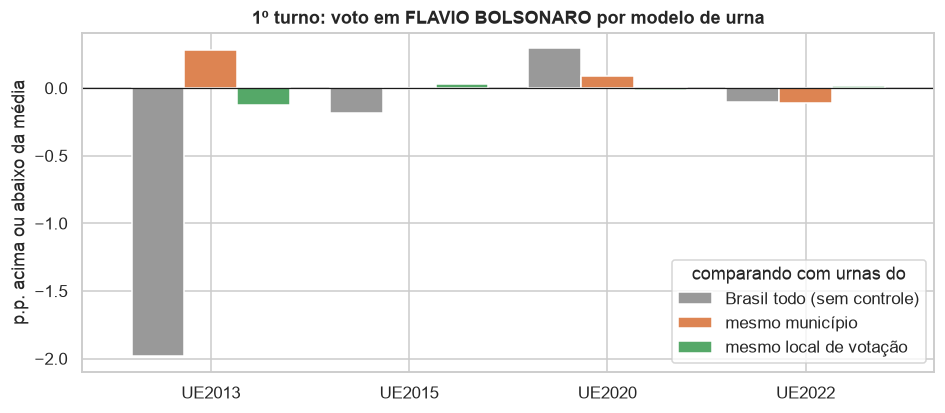

2º turno: modelo identificado em 100.0% das seções (100.0% pela seção, o resto pelo número da urna)


% de LULA por modelo de urna


,seções,ingênuo (% média),dentro do município (p.p.),seções em município misto,dentro do local de votação (p.p.),seções em local de votação misto
modelo_urna,,,,,,
UE2013,10894,53.911,-0.336,8950,0.132,5225
UE2015,87781,51.977,-0.036,69773,-0.034,16050
UE2020,200463,51.526,-0.116,76223,0.013,22444
UE2022,198759,51.829,0.187,75673,-0.019,21698


   amplitude ingênua: 2.4 p.p. | dentro do município: 0.52 p.p. | dentro do local: 0.17 p.p.


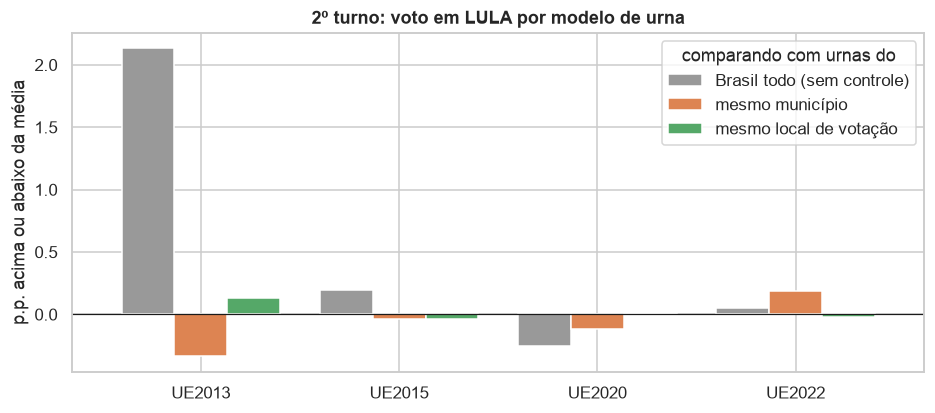

In [9]:
ARQ_MODELO = A.PROCESSED / "modelo_urna.parquet"
if not ARQ_MODELO.exists():
    print("Rode `uv run modelo-urna` para ter o modelo da urna; esta seção fica de fora.")
else:
    MOD = pd.read_parquet(ARQ_MODELO)
    por_urna = MOD.drop_duplicates("nr_urna").set_index("nr_urna")["modelo_urna"]
    for t in TURNOS:
        df = T[t]
        a, _ = A.principais(df, 2)
        d = df[(df["votos_validos"] > 0) & (df["uf"] != "ZZ")].copy()
        d = d.merge(MOD[["uf", "cd_municipio", "nr_zona", "nr_secao", "modelo_urna"]], on=["uf", "cd_municipio", "nr_zona", "nr_secao"], how="left")
        sem = d["modelo_urna"].isna()
        d.loc[sem, "modelo_urna"] = pd.to_numeric(d.loc[sem, "nr_urna_efetivada"], errors="coerce").map(por_urna)
        print(f"{t}º turno: modelo identificado em {d['modelo_urna'].notna().mean():.1%} das seções "
              f"({(~sem).mean():.1%} pela seção, o resto pelo número da urna)")
        d = d.dropna(subset=["modelo_urna"])
        d["sh"] = d[a] / d["votos_validos"] * 100
        w = d["votos_validos"]
        out = pd.DataFrame({"seções": d["modelo_urna"].value_counts().sort_index(),
                            "ingênuo (% média)": d.groupby("modelo_urna").apply(lambda g: np.average(g["sh"], weights=g["votos_validos"]))})
        for nome, grupo in (("município", ["uf", "cd_municipio"]), ("local de votação", ["uf", "cd_municipio", "nr_zona", "nr_local_votacao"])):
            g = d.groupby(grupo, observed=True)
            # só grupos com mais de um modelo informam a comparação
            mistos = g["modelo_urna"].transform("nunique") > 1
            media = (d["sh"] * w).groupby([d[c] for c in grupo]).transform("sum") / w.groupby([d[c] for c in grupo]).transform("sum")
            dm = (d["sh"] - media)[mistos]
            out[f"dentro do {nome} (p.p.)"] = dm.groupby(d.loc[mistos, "modelo_urna"]).apply(lambda s: np.average(s, weights=w[s.index]))
            out[f"seções em {nome} misto"] = mistos.groupby(d["modelo_urna"]).sum()
        print(f"% de {a} por modelo de urna")
        display(out)
        print(f"   amplitude ingênua: {out['ingênuo (% média)'].max() - out['ingênuo (% média)'].min():.1f} p.p. | "
              f"dentro do município: {out['dentro do município (p.p.)'].max() - out['dentro do município (p.p.)'].min():.2f} p.p. | "
              f"dentro do local: {out['dentro do local de votação (p.p.)'].max() - out['dentro do local de votação (p.p.)'].min():.2f} p.p.")
        # mesma escala nas três comparações, para que a diferença bruta e a controlada se vejam lado a lado
        g = pd.DataFrame({"Brasil todo (sem controle)": out["ingênuo (% média)"] - np.average(d["sh"], weights=w),
                          "mesmo município": out["dentro do município (p.p.)"],
                          "mesmo local de votação": out["dentro do local de votação (p.p.)"]})
        ax = g.plot.bar(rot=0, width=.8, color=["0.6", "C1", "C2"], figsize=(10, 4))
        ax.axhline(0, color="k", lw=.8); ax.set_xlabel("")
        ax.set_ylabel("p.p. acima ou abaixo da média")
        ax.set_title(f"{t}º turno: voto em {a} por modelo de urna", weight="bold")
        ax.legend(title="comparando com urnas do"); plt.show()

**Leitura.** A diferença bruta entre modelos (cerca de 2 p.p. no 1º turno) quase some quando se comparam urnas do mesmo
município e some de vez dentro do mesmo local de votação (décimos de ponto, para os dois lados). Ela vem de onde cada
modelo foi instalado, não do modelo. O argumento de 2022 de que as urnas antigas votavam diferente não se sustenta nestes dados.

## A9. "Virada" durante a apuração
**Hipótese:** a liderança mudou durante a totalização, o que indicaria inserção de votos no fim.
**Controle:** a ordem de chegada dos BUs não é aleatória — capitais e Sul/Sudeste chegam primeiro, Norte/Nordeste e
exterior depois. Verificamos se, **dentro de cada UF**, os BUs que chegaram por último votam diferente dos primeiros.

In [10]:
for t in TURNOS:
    df = T[t].dropna(subset=["dt_bu_recebido"]).copy()
    a, b = A.principais(df, 2)
    df["quintil_chegada_na_uf"] = df.groupby("uf", observed=True)["dt_bu_recebido"].rank(pct=True).mul(5).clip(upper=4.999).astype(int) + 1
    g = df.groupby("quintil_chegada_na_uf")[[a, "votos_validos"]].sum()
    gl = df.assign(q=pd.qcut(df["dt_bu_recebido"].rank(method="first"), 5, labels=range(1, 6))).groupby("q", observed=True)[[a, "votos_validos"]].sum()
    out = pd.DataFrame({f"% {a} — quintil nacional de chegada": gl[a] / gl["votos_validos"] * 100,
                        f"% {a} — quintil de chegada dentro da UF": (g[a] / g["votos_validos"] * 100).values})
    display(out.style.set_caption(f"{t}º turno"))

,% FLAVIO BOLSONARO — quintil nacional de chegada,% FLAVIO BOLSONARO — quintil de chegada dentro da UF
q,,
1,51.120493,48.681342
2,49.847270,48.012972
3,48.283909,47.170150
4,46.043179,46.612325
5,40.393091,44.824359


,% LULA — quintil nacional de chegada,% LULA — quintil de chegada dentro da UF
q,,
1,49.594194,50.899633
2,49.979132,51.101632
3,52.012220,51.591501
4,53.471198,52.186566
5,53.812400,53.153655


## A10. Seções que destoam do próprio local de votação — há direção?
**Hipótese:** se houvesse manipulação a favor de um candidato, as seções muito destoantes do resto da escola
estariam **desequilibradas** para um lado.
**Controle:** comparamos o número observado com a simulação sob acaso e verificamos a simetria (z > 5 vs z < −5).
Atenção: assimetria também pode ter causa legítima e sistemática — seções do mesmo prédio nem sempre têm eleitorado
equivalente (seções criadas para novos eleitores, transferidos, seções com acessibilidade que concentram idosos e pessoas
com deficiência, presos provisórios). Cada seção listada precisa ser checada contra esse tipo de explicação.
**Resultado da checagem (notebook 03):** a mesma assimetria aparece em 2022, na mesma direção, e mais da metade das seções
extremas é a **última seção do local** (a mais nova), que concentra eleitores jovens e transferidos. O perfil do eleitorado
por seção mostra que cerca de 60% das seções extremas (medidas para Lula) têm mais de 10 p.p. a mais de eleitores de 16–24 anos que o resto do
prédio (contra 7% das seções em geral).

In [11]:
for t in TURNOS:
    df = T[t]
    a, _ = A.principais(df, 2)
    r = A.desvio_no_local(df, a)
    sim = A.simular_extremos(r, 5)
    pos, neg = int((r.tabela["z"] > 5).sum()), int((r.tabela["z"] < -5).sum())
    print(f"{t}º turno: |z|>5 observado {sim['observado']} vs acaso ~{sim['esperado_medio']:.0f} (p99 {sim['esperado_p99']:.0f}); "
          f"a favor de {a}: {pos}, contra: {neg}")
    from scipy.stats import binomtest
    if pos + neg:
        print(f"   teste de simetria (binomial): p = {binomtest(pos, pos + neg).pvalue:.3g}")
    sinalizar(t, "A10 seção |z|>5 vs próprio local", df["sec_id"].isin(r.tabela.loc[r.tabela["z"].abs() > 5, "sec_id"]))
    ext = r.tabela[r.tabela["z"].abs() > 5].merge(df[["sec_id", "nm_municipio", "qt_aptos", "comparecimento_pct"]], on="sec_id")
    ultima = df.groupby(A.CHAVE_LOCAL, observed=True)["nr_secao"].transform("max") == df["nr_secao"]
    print(f"   {ext['sec_id'].isin(df.loc[ultima, 'sec_id']).mean():.0%} das seções |z|>5 são a última seção do local "
          f"(entre todas as seções: {ultima.mean():.0%})")
    display(ext.groupby("uf", observed=True).size().sort_values(ascending=False).head(10).rename("seções |z|>5").to_frame().T)
    display(ext.sort_values("z")[["sec_id", "nm_municipio", "n_secoes_local", "qt_aptos", "votos_validos", "prop", "prop_esperada", "z"]].head(15))

1º turno: |z|>5 observado 95 vs acaso ~1 (p99 2); a favor de FLAVIO BOLSONARO: 28, contra: 67
   teste de simetria (binomial): p = 7.8e-05
[1º turno] A10 seção |z|>5 vs próprio local: 95 seções (0.019%), 25,488 votos válidos | líquido p/ vencedor -5,947 = -0.27% da margem → não altera o resultado


   60% das seções |z|>5 são a última seção do local (entre todas as seções: 19%)


uf,SP,SC,PR,BA,ZZ,RS,RJ,PI,CE,ES
seções |z|>5,16,9,9,8,6,6,6,5,5,5


,sec_id,nm_municipio,n_secoes_local,qt_aptos,votos_validos,prop,prop_esperada,z
73,SP-62499-26-402,BOTUCATU,11,316,291,0.192,0.536,-8.999
28,MG-41238-32-336,BELO HORIZONTE,12,398,374,0.136,0.434,-8.887
91,ZZ-30341-1-3116,PORTO,58,786,437,0.172,0.385,-7.021
10,CE-14796-44-148,MORRINHOS,3,245,214,0.332,0.631,-6.958
56,RN-18856-14-110,TOUROS,3,356,311,0.164,0.413,-6.843
77,SP-62197-23-463,BAURU,13,226,214,0.266,0.567,-6.797
75,SP-70793-121-451,SÃO CARLOS,9,268,258,0.132,0.397,-6.673
58,RS-88013-2-383,PORTO ALEGRE,13,375,321,0.293,0.535,-6.655
20,ES-57053-52-686,VITÓRIA,12,392,319,0.317,0.556,-6.592
50,RJ-58653-71-458,NITERÓI,7,293,278,0.137,0.384,-6.506


2º turno: |z|>5 observado 110 vs acaso ~1 (p99 3); a favor de LULA: 75, contra: 35
   teste de simetria (binomial): p = 0.000172
[2º turno] A10 seção |z|>5 vs próprio local: 110 seções (0.022%), 30,668 votos válidos | líquido p/ vencedor +7,826 = 0.18% da margem → não altera o resultado


   57% das seções |z|>5 são a última seção do local (entre todas as seções: 19%)


uf,SP,BA,ZZ,SC,RS,CE,MG,PR,ES,RJ
seções |z|>5,20,14,10,9,9,7,7,6,5,4


,sec_id,nm_municipio,n_secoes_local,qt_aptos,votos_validos,prop,prop_esperada,z
32,MA-9610-71-468,AÇAILÂNDIA,3,278,238,0.366,0.793,-12.370
46,PE-25852-79-157,MOREILÂNDIA,5,244,193,0.798,0.949,-7.315
68,RS-87556-117-66,NÃO-ME-TOQUE,4,315,259,0.158,0.444,-7.049
48,PE-23337-45-238,BELO JARDIM,3,346,302,0.556,0.773,-6.841
11,BA-39918-168-179,TANQUE NOVO,3,296,233,0.790,0.934,-6.716
102,ZZ-29351-1-1564,BARCELONA,22,798,235,0.553,0.782,-6.448
67,RS-86479-4-4,ESPUMOSO,3,364,303,0.284,0.526,-6.413
0,AC-1104-5-66,JORDÃO,3,200,142,0.993,1.000,-6.296
12,BA-35335-64-188,GUANAMBI,4,399,348,0.555,0.746,-6.253
7,BA-30007-205-227,LUÍS EDUARDO MAGALHÃES,7,380,309,0.104,0.319,-6.193


## A11. Comportamento entre turnos
**Hipótese:** seções onde o finalista ganhou muito mais (ou o comparecimento subiu muito) do que o perfil do 1º turno
permite prever seriam alvo de manipulação no 2º turno. Também: troca da urna física entre turnos.
**Cuidado:** o modelo é linear e a migração dos votos de 3º colocados não é; por isso os resíduos podem ser assimétricos
mesmo sem nenhuma manipulação (isso foi verificado com um 2º turno sintético e limpo). Assimetria aqui não é prova.

In [12]:
if 2 not in TURNOS:
    print("2º turno ainda não disponível — seção pulada.")
else:
    M = A.juntar_turnos(T[1], T[2])
    alvo = A.principais(T[2], 1)[0]
    TR = A.modelo_transicao(M, A.candidatos(T[1])[:8], alvo)
    pos, neg = int((TR["z"] > 5).sum()), int((TR["z"] < -5).sum())
    print(f"Resíduo |z|>5 do modelo 1º→2º turno: {pos} a favor de {alvo}, {neg} contra (R² = {TR.attrs['r2']:.3f})")
    sinalizar(2, "A11a resíduo 1º→2º turno |z|>5", T[2]["sec_id"].isin(TR.loc[TR["z"].abs() > 5, "sec_id"]))
    dc = M["qt_comparecimento_2t"] / M["qt_aptos_2t"] - M["qt_comparecimento_1t"] / M["qt_aptos_1t"]
    sinalizar(2, "A11b comparecimento subiu > 15 p.p.", T[2]["sec_id"].isin(M.loc[dc > .15, "sec_id"]))
    troca = M["nr_urna_efetivada_1t"].notna() & (M["nr_urna_efetivada_1t"] != M["nr_urna_efetivada_2t"])
    sinalizar(2, "A11c urna física diferente entre turnos", T[2]["sec_id"].isin(M.loc[troca, "sec_id"]))

Resíduo |z|>5 do modelo 1º→2º turno: 392 a favor de LULA, 54 contra (R² = 0.092)
[2º turno] A11a resíduo 1º→2º turno |z|>5: 446 seções (0.089%), 102,112 votos válidos | líquido p/ vencedor +61,478 = 1.39% da margem → não altera o resultado
[2º turno] A11b comparecimento subiu > 15 p.p.: 71 seções (0.014%), 15,500 votos válidos | líquido p/ vencedor +10,202 = 0.23% da margem → não altera o resultado
[2º turno] A11c urna física diferente entre turnos: 4,435 seções (0.888%), 1,104,599 votos válidos | líquido p/ vencedor +44,487 = 1.00% da margem → não altera o resultado


## Materialidade — o placar final da contestação
Para cada critério: quantas seções, quantos votos, e quanto da margem seria revertido se **todas** as seções
sinalizadas fossem anuladas. A última linha é o **cenário máximo**: anular toda seção que caiu em *qualquer* critério.

In [13]:
for t in TURNOS:
    df = T[t]
    linhas = [A.impacto(df, m, n) for n, m in FLAGS[t].items()]
    uniao = pd.concat(FLAGS[t].values(), axis=1).any(axis=1) if FLAGS[t] else pd.Series(False, index=df.index)
    linhas.append(A.impacto(df, uniao, "CENÁRIO MÁXIMO (união de todos)"))
    tab = pd.DataFrame(linhas).set_index("criterio")
    display(tab[["secoes", "pct_secoes", "votos_validos", "liquido_para_vencedor", "pct_da_margem", "muda_resultado"]]
            .style.set_caption(f"{t}º turno — margem: {tab['margem_total'].iloc[0]:,} votos")
            .format({"secoes": "{:,}", "votos_validos": "{:,}", "liquido_para_vencedor": "{:+,}", "pct_secoes": "{:.3f}", "pct_da_margem": "{:.2f}%"}))
    FLAGS[t]["_uniao"] = uniao

,secoes,pct_secoes,votos_validos,liquido_para_vencedor,pct_da_margem,muda_resultado
criterio,,,,,,
A1 conta não fecha,0,0.000,0,+0,0.00%,False
A2 seção extrema destoando do próprio local,4,0.001,579,-373,-0.02%,False
A3 comparecimento ≥95%,538,0.108,"79,641","-23,661",-1.06%,False
"A4 sem biometria > p99,9 (29%)",500,0.100,"94,718","-10,294",-0.46%,False
A5a abertura antes de 7h50 (Brasília),0,0.000,0,+0,0.00%,False
A5b encerramento antes de 17h (Brasília),0,0.000,0,+0,0.00%,False
A5c BU emitido antes do encerramento,0,0.000,0,+0,0.00%,False
A5d BU emitido > 2h após encerramento,2,0.000,382,-88,-0.00%,False
A5e urna carregada no dia da eleição ou depois,7,0.001,"1,675",+684,0.03%,False


,secoes,pct_secoes,votos_validos,liquido_para_vencedor,pct_da_margem,muda_resultado
criterio,,,,,,
A1 conta não fecha,0,0.000,0,+0,0.00%,False
A2 seção extrema destoando do próprio local,2,0.000,271,+113,0.00%,False
A3 comparecimento ≥95%,620,0.124,"107,297","+37,441",0.85%,False
"A4 sem biometria > p99,9 (28%)",500,0.100,"97,545","+19,403",0.44%,False
A5a abertura antes de 7h50 (Brasília),0,0.000,0,+0,0.00%,False
A5b encerramento antes de 17h (Brasília),0,0.000,0,+0,0.00%,False
A5c BU emitido antes do encerramento,0,0.000,0,+0,0.00%,False
A5d BU emitido > 2h após encerramento,10,0.002,"3,090",-294,-0.01%,False
A5e urna carregada no dia da eleição ou depois,5,0.001,"1,072",-222,-0.01%,False


## A menor brecha possível
Pergunta direta: **qual o menor número de seções que, anuladas, inverteria o resultado?** Escolhemos as seções mais
favoráveis ao vencedor (maior saldo líquido) até zerar a margem. Depois verificamos quantas delas foram sinalizadas por
algum critério acima — isto é, quantas teriam **alguma** justificativa técnica para um pedido de anulação.

In [14]:
for t in TURNOS:
    df = T[t]
    v, s, m = A.margem(df)
    saldo = (df[v] - df[s]).sort_values(ascending=False)
    acum = saldo.cumsum()
    n_min = int((acum < m).sum()) + 1
    alvo = saldo.index[:n_min]
    sinal = FLAGS[t]["_uniao"].loc[alvo]
    print(f"{t}º turno: margem {m:,}. Anulando as seções mais favoráveis a {v}, seriam necessárias {n_min:,} seções "
          f"({n_min/len(df)*100:.2f}% do total; {df.loc[alvo,'votos_validos'].sum()/df['votos_validos'].sum()*100:.1f}% dos votos válidos).")
    print(f"   Dessas, {int(sinal.sum()):,} ({sinal.mean()*100:.2f}%) caíram em algum critério de anomalia.")
    print(f"   Seções sinalizadas no total: {int(FLAGS[t]['_uniao'].sum()):,}; saldo líquido delas para {v}: "
          f"{int(saldo.reindex(df.index[FLAGS[t]['_uniao']]).sum()):+,} votos.")
    print(f"   Limite do art. 224 (nulidade de mais da metade dos votos): {df['votos_total'].sum()//2:,} votos.")

1º turno: margem 2,224,965. Anulando as seções mais favoráveis a FLAVIO BOLSONARO, seriam necessárias 13,453 seções (2.69% do total; 3.2% dos votos válidos).
   Dessas, 507 (3.77%) caíram em algum critério de anomalia.
   Seções sinalizadas no total: 17,268; saldo líquido delas para FLAVIO BOLSONARO: -673,753 votos.
   Limite do art. 224 (nulidade de mais da metade dos votos): 62,637,917 votos.
2º turno: margem 4,430,191. Anulando as seções mais favoráveis a LULA, seriam necessárias 23,770 seções (4.76% do total; 5.3% dos votos válidos).
   Dessas, 3,348 (14.08%) caíram em algum critério de anomalia.
   Seções sinalizadas no total: 21,983; saldo líquido delas para LULA: +997,137 votos.
   Limite do art. 224 (nulidade de mais da metade dos votos): 64,118,037 votos.


## Veredito
A célula abaixo resume, critério por critério, se a "brecha" é **material** (reverte a margem por si só) e se o padrão
**sobreviveu ao controle** — essa parte é qualitativa e deve ser preenchida lendo os resultados de cada seção acima.

Leitura honesta para quem quer contestar: um argumento só é utilizável se (1) apontar seções concretas, (2) tiver uma
irregularidade verificável no BU impresso, log da urna ou ata, e (3) somar votos suficientes para mudar o resultado.
Anomalias estatísticas que desaparecem com controle geográfico, ou que atingem os dois candidatos de forma simétrica,
não atendem a nenhum dos três.

In [15]:
for t in TURNOS:
    tab = pd.DataFrame([A.impacto(T[t], mk, n) for n, mk in FLAGS[t].items() if not n.startswith("_")])
    if tab.empty:
        continue
    tab["veredito"] = np.select(
        [tab["secoes"] == 0, tab["muda_resultado"], tab["liquido_para_vencedor"] <= 0, tab["pct_da_margem"] >= 10],
        ["nada encontrado", "MATERIAL — exigiria prova concreta seção a seção",
         "anular favoreceria o próprio vencedor", "relevante, mas insuficiente sozinho"],
        "imaterial")
    print(f"\n{t}º turno")
    display(tab.set_index("criterio")[["secoes", "pct_da_margem", "veredito"]])


1º turno


,secoes,pct_da_margem,veredito
criterio,,,
A1 conta não fecha,0,0.000,nada encontrado
A2 seção extrema destoando do próprio local,4,-0.017,anular favoreceria o próprio vencedor
A3 comparecimento ≥95%,538,-1.063,anular favoreceria o próprio vencedor
"A4 sem biometria > p99,9 (29%)",500,-0.463,anular favoreceria o próprio vencedor
A5a abertura antes de 7h50 (Brasília),0,0.000,nada encontrado
A5b encerramento antes de 17h (Brasília),0,0.000,nada encontrado
A5c BU emitido antes do encerramento,0,0.000,nada encontrado
A5d BU emitido > 2h após encerramento,2,-0.004,anular favoreceria o próprio vencedor
A5e urna carregada no dia da eleição ou depois,7,0.031,imaterial



2º turno


,secoes,pct_da_margem,veredito
criterio,,,
A1 conta não fecha,0,0.000,nada encontrado
A2 seção extrema destoando do próprio local,2,0.003,imaterial
A3 comparecimento ≥95%,620,0.845,imaterial
"A4 sem biometria > p99,9 (28%)",500,0.438,imaterial
A5a abertura antes de 7h50 (Brasília),0,0.000,nada encontrado
A5b encerramento antes de 17h (Brasília),0,0.000,nada encontrado
A5c BU emitido antes do encerramento,0,0.000,nada encontrado
A5d BU emitido > 2h após encerramento,10,-0.007,anular favoreceria o próprio vencedor
A5e urna carregada no dia da eleição ou depois,5,-0.005,anular favoreceria o próprio vencedor
